<a href="https://colab.research.google.com/github/mizcheeese/Week-six/blob/main/week-06/archaeo-stats-in-R.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# simple statistics in R for archaeologists

Now, Kevin Gratski has an excellent course on 'Digital Archaeology and Data Reuse', https://github.com/kgarstki/Introduction-Digital-Archaeology-Course and we are going to follow what he does with his class here:  https://github.com/kgarstki/ANTH-641_Stats-with-R

This document is a remix of that one. Make sure to read all comments carefully.

In [1]:
# The "archdata" package was created by David L. Carlson and Georg Roth for
# "Quantitative Methods in Archaeology Using R" by David L. Carlson (2017).

install.packages("archdata")
install.packages(c("RcmdrMisc")) # I fixed the error

# you'll get some warnings, but you can ignore them. This might take a few moments.

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘fracdiff’, ‘lmtest’, ‘timeDate’, ‘urca’, ‘RcppArmadillo’, ‘cowplot’, ‘Deriv’, ‘forecast’, ‘rbibutils’, ‘numDeriv’, ‘doBy’, ‘SparseM’, ‘MatrixModels’, ‘Rdpack’, ‘minqa’, ‘nloptr’, ‘reformulas’, ‘RcppEigen’, ‘checkmate’, ‘carData’, ‘Formula’, ‘pbkrtest’, ‘quantreg’, ‘lme4’, ‘zoo’, ‘gridExtra’, ‘htmlTable’, ‘proxy’, ‘car’, ‘sandwich’, ‘abind’, ‘colorspace’, ‘Hmisc’, ‘e1071’, ‘readstata13’, ‘nortest’




Tip: you can go to [rdocumentation.org](https://www.rdocumentation.org/packages/archdata/versions/1.2-1) to see the information about all of the different archaeological datasets that have been packaged into 'archdata'. For instance, we're about to explore the 'DartPoints' dataset. Metadata about that dataset is directly behind [this link](https://www.rdocumentation.org/packages/archdata/versions/1.2-1/topics/DartPoints). Go have a look.

In [2]:
# ok, tell R we want to use those two packages:
library(archdata)
library(RcmdrMisc)

Loading required package: car

Loading required package: carData

Loading required package: sandwich



# 1. Initial exploration for numerical and categorical data

Once you've collected data, you will want to explore the distribution of that data. We can look for the average values, or the most frequently occuring values (mean and median). We can look for how dispersed the data are around those central tendencies by looking for standard deviation or variance. Remember, we're trying to create some fragment of a past world from these observations; data don't tell a story, but they become something from which a story can be told.


In [3]:
# Because the data is already packaged up for us in archdata, we can load it up with the 'data' command.
# Most of the time though we'd have to write a small function to read the data in from a csv file.
# Here we'll load up the 'DartPoints' dataframe:
data(DartPoints)
View(DartPoints) # notice that View starts with a capital V. Other commands don't. Annoying. Lower-case 'view' will give you an error.



,Name,Catalog,TARL,Quad,Length,Width,Thickness,B.Width,J.Width,H.Length,Weight,Blade.Sh,Base.Sh,Should.Sh,Should.Or,Haft.Sh,Haft.Or
,<fct>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>
1,Darl,41-0322,41CV0536,26/59,42.8,15.8,5.8,11.3,10.6,11.6,3.6,S,I,S,T,S,E
2,Darl,35-2946,41CV0235,21/63,40.5,17.4,5.8,NA,13.7,12.9,4.5,S,I,S,T,S,E
3,Darl,35-2921,41CV0132,20/63,37.5,16.3,6.1,12.1,11.3,8.2,3.6,S,I,S,T,S,E
4,Darl,36-3487,41CV0594,10/54,40.3,16.1,6.3,13.5,11.7,8.3,4.0,S,I,S,T,S,E
5,Darl,36-3321,41CV1023,12/58,30.6,17.1,4.0,12.6,11.2,8.9,2.3,S,I,S,T,S,E
6,Darl,35-2959,41CV0235,21/63,41.8,16.8,4.1,12.7,11.5,11.0,3.0,S,E,I,T,I,C
7,Darl,35-2866,41CV0855,25/65,40.3,20.7,5.9,11.7,11.4,7.6,3.9,I,I,S,T,I,E
8,Darl,41-0323,41CV0536,26/59,48.5,18.7,6.9,14.7,13.4,9.2,6.2,E,I,I,T,S,E
9,Darl,35-2325,41CV0795,20/48,47.7,17.5,7.2,14.3,11.8,8.9,5.1,E,S,I,H,S,E


In [31]:
# Three ways of finding the average length of the dart points:
mean(DartPoints[,"Length"])
# All three commands are equivalent. First, we tell R we want the mean, and then inside the brackets we
# tell it WHAT we want mean to be calculated on. In the first example, we give the name of the dataframe
# and then use the $ operator to specify which column by name. In the second, we give the name of the dataframe
# and then indicate the position that we want: the 5th column. The third specifies position, but uses the name of the column.


[1] 49.3

In [5]:
# You can calculate each descriptive statistic one at a time, or you can get R to give you:
summary(DartPoints$Length)


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  30.60   40.85   47.10   49.33   55.80  109.50 

In [6]:
# So let's indicate the number of significant digits we want (places after the decimal) and then
# get R to give us a summary for *all* the columns, from the 5th position to the 11th:
options(digits=3)
numSummary(DartPoints[, 5:11])

           mean    sd   IQR   0%   25%  50%   75%  100%  n NA
Length    49.33 12.74 14.95 30.6 40.85 47.1 55.80 109.5 91  0
Width     22.08  5.16  6.60 14.5 18.55 21.1 25.15  49.3 91  0
Thickness  7.27  1.53  2.00  4.0  6.25  7.2  8.25  10.7 91  0
B.Width   13.75  2.95  3.80  7.1 11.70 13.6 15.50  21.2 69 22
J.Width   15.40  2.73  3.95 10.6 13.12 15.6 17.08  21.2 90  1
H.Length  13.41  4.01  5.80  5.8 10.50 12.5 16.30  23.3 91  0
Weight     7.64  4.21  5.50  2.3  4.55  6.8 10.05  28.8 91  0

In [7]:
# What happens if you try to include columns 1 to 4?




In [8]:
# How many points are there for each type of point? The type is in the 'Name' column.
# We make a new variable called DP_Type, and it gets the results of the command
# table(DartPoints$Name).

# The outer parentheses are a short cut to print the result of what goes inside DP_Type.
(DP_Type <- table(DartPoints$Name))

# We can work out the proportion each type has using prop.table on DP_Type, then multiplying by 100.
prop.table(DP_Type)*100


      Darl      Ensor Pedernales     Travis      Wells 
        28         10         32         11         10 


      Darl      Ensor Pedernales     Travis      Wells 
      30.8       11.0       35.2       12.1       11.0 

## Initial exploration for categorical data

In DartPoints, there's a lot of data about the kind of blade, and the shape of the blade. These are categories; something either is in one category, or another. So one thing we can do is see how they relate to each other by cross tabulation.

In [9]:
# Here, we create a new variable to contain the results of the xtabs command. You can almost read
# the code like this: DP_CT gets the results of xtabs of Name versus Blade.Sh from DartPoints.

(DP_CT <- xtabs(~Name+Blade.Sh, DartPoints))

            Blade.Sh
Name          E  I  R  S
  Darl       15  2  0 10
  Ensor       2  1  0  6
  Pedernales 15  1  3 13
  Travis      7  0  0  4
  Wells       3  0  0  7

In [10]:
# We can add up each row and column by using the addmargins command:
addmargins(DP_CT)

,E,I,R,S,Sum
Darl,15,2,0,10,27
Ensor,2,1,0,6,9
Pedernales,15,1,3,13,32
Travis,7,0,0,4,11
Wells,3,0,0,7,10
Sum,42,4,3,40,89


In [11]:
# The bottom right hand corner shows us how many records we've added: 89. But do we have all the data? Let's check
# with the `dim` command (dimension):
dim(DartPoints)

[1] 91 17

In [12]:
# that command tells us we've got 91 rows and 17 columns. So DP_CT is missing some data!
# What gives? If you look at DartPoints:
View(DartPoints)

,Name,Catalog,TARL,Quad,Length,Width,Thickness,B.Width,J.Width,H.Length,Weight,Blade.Sh,Base.Sh,Should.Sh,Should.Or,Haft.Sh,Haft.Or
,<fct>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>
1,Darl,41-0322,41CV0536,26/59,42.8,15.8,5.8,11.3,10.6,11.6,3.6,S,I,S,T,S,E
2,Darl,35-2946,41CV0235,21/63,40.5,17.4,5.8,NA,13.7,12.9,4.5,S,I,S,T,S,E
3,Darl,35-2921,41CV0132,20/63,37.5,16.3,6.1,12.1,11.3,8.2,3.6,S,I,S,T,S,E
4,Darl,36-3487,41CV0594,10/54,40.3,16.1,6.3,13.5,11.7,8.3,4.0,S,I,S,T,S,E
5,Darl,36-3321,41CV1023,12/58,30.6,17.1,4.0,12.6,11.2,8.9,2.3,S,I,S,T,S,E
6,Darl,35-2959,41CV0235,21/63,41.8,16.8,4.1,12.7,11.5,11.0,3.0,S,E,I,T,I,C
7,Darl,35-2866,41CV0855,25/65,40.3,20.7,5.9,11.7,11.4,7.6,3.9,I,I,S,T,I,E
8,Darl,41-0323,41CV0536,26/59,48.5,18.7,6.9,14.7,13.4,9.2,6.2,E,I,I,T,S,E
9,Darl,35-2325,41CV0795,20/48,47.7,17.5,7.2,14.3,11.8,8.9,5.1,E,S,I,H,S,E


In [13]:
# you'll see we're missing cells of data. That might be the issue. So let's add the missing data
# to our cross tabulation:

addmargins(xtabs(~Name+addNA(Blade.Sh), DartPoints))

,E,I,R,S,NA,Sum
Darl,15,2,0,10,1,28
Ensor,2,1,0,6,1,10
Pedernales,15,1,3,13,0,32
Travis,7,0,0,4,0,11
Wells,3,0,0,7,0,10
Sum,42,4,3,40,2,91


## YOUR TURN #1

Add another dataframe from archdata, and explore the numerical and categorical data. Write down any patterns you see. Remember, you can go to [https://www.rdocumentation.org/packages/archdata/versions/1.2-1](https://www.rdocumentation.org/packages/archdata/versions/1.2-1) to see what other data is there, and then load it here by name with the `data(name-goes-here)` command


In [14]:
# put your stuff in here

# 2. Graphs
Looking at data with Graphs - Often, graphs provide us with a good summary of data and can help illuminate patterns.

In [15]:

# We're going to look at two ways to visualize the number of coils present on La Tène fibulae
# from the Iron Age cemetery of Münsingen near Berne, Switzerland. Bring the dataframe into your directory.
data(Fibulae)
View(Fibulae)

Grave,Mno,FL,BH,BFA,FA,CD,BRA,ED,FEL,C,BW,BT,FEW,Coils,Length
<chr>,<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<int>,<int>
149,389,93,24,7,10,16,1,13,31,47,3.5,3.5,NA,4,114
190,615,21,7,6,9,6,5,2,11,10,3.5,1.7,NA,12,35
161,125,33,15,2,8,7,3,8,10,20,3.9,3.2,NA,4,60
31,812,23,26,4,7,9,5,12,1,16,6.2,7.7,2.8,4,74
49,798,20,23,2,8,7,1,8,5,16,7.7,5.2,2.6,6,68
6,673,27,15,6,8,7,5,3,11,11,3.7,3.5,1.8,4,55
Thames,Thames,10,16,1,10,9,1,7,0,11,6.1,4.1,0.0,4,45
23,643,15,18,1,10,10,1,5,0,15,3.5,3.5,0.0,4,40
149,391,31,13,4,9,7,4,5,11,18,17.6,1.4,3.6,6,54


In [16]:
# We're interested in the variable "Coils"
(Fib_coils <- table(Fibulae$Coils))



 3  4  6 10 12 22 
 1 12 13  1  2  1 

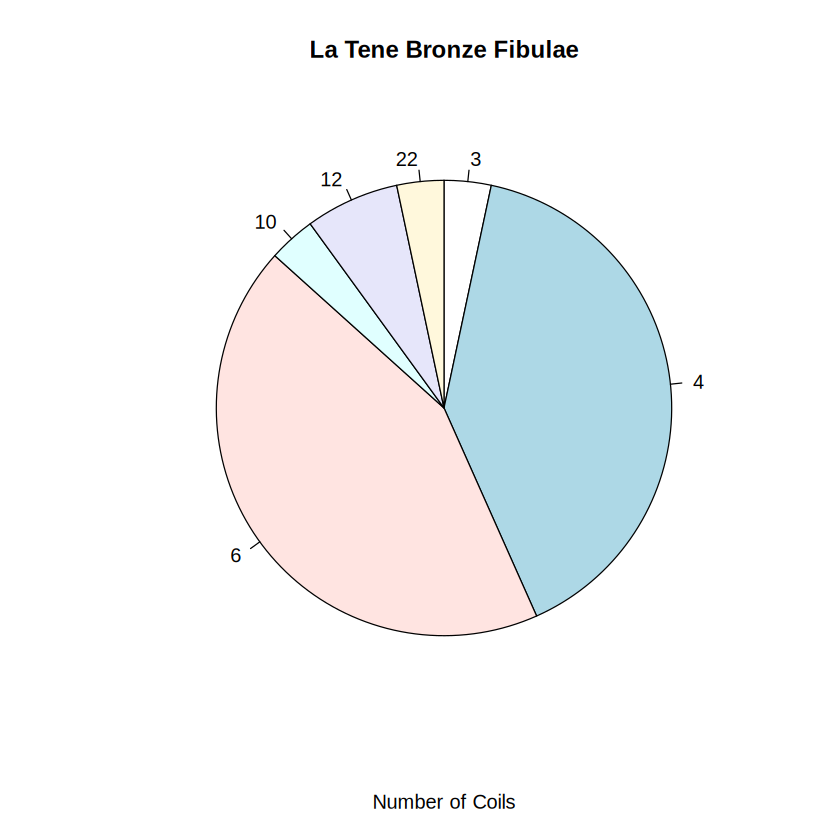

In [17]:
# First we'll make a pie chart of the number of coils. We'll include a main title and title our variable.
pie(Fib_coils, main="La Tene Bronze Fibulae", xlab="Number of Coils", clockwise=TRUE)
# Beautiful!

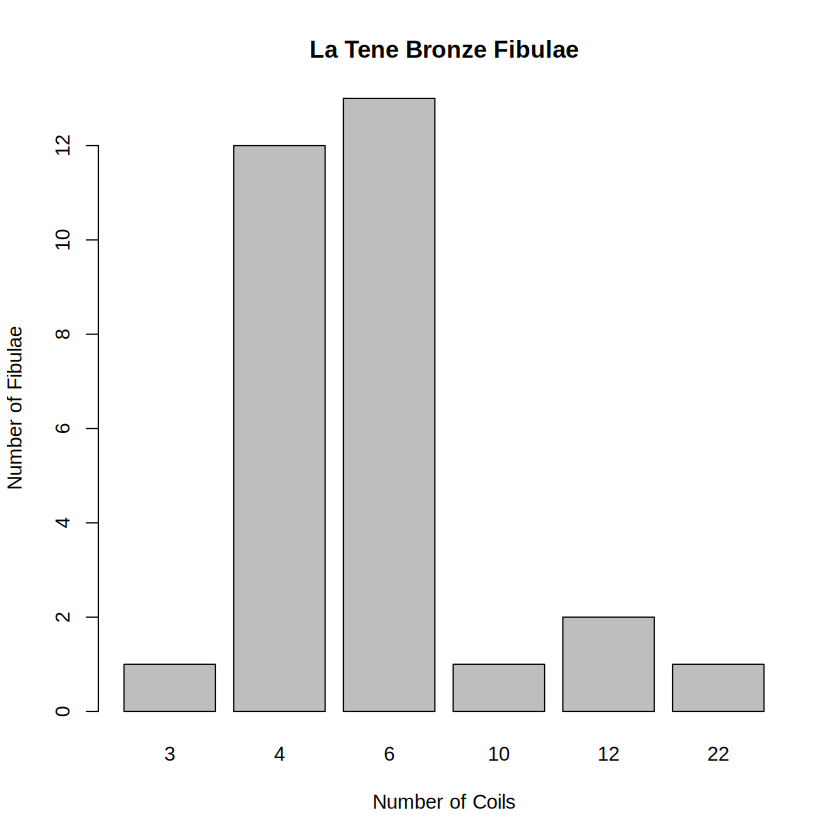

In [18]:
# Let's compare it to a barplot of the same data.
barplot(Fib_coils, main="La Tene Bronze Fibulae", xlab="Number of Coils", ylab="Number of Fibulae")
# Which way to visualize the data is more helpful?

In [19]:
# We'll try one more graph, using more complex data. First bring the dataframe Pithouses into the directory.
# This includes the desription of 45 Arctic Norway pithouses with 6 categorical variables.
data(PitHouses)

In [20]:
# Then we'll create a cross-tabulation of Hearths with Size
(PitHouses.tbl <- xtabs(~Hearths+Size, PitHouses))

               Size
Hearths         Small Medium Large
  None              3      3     1
  One               6      3     0
  Two               4     10     1
  Charcoal Conc     8      5     1

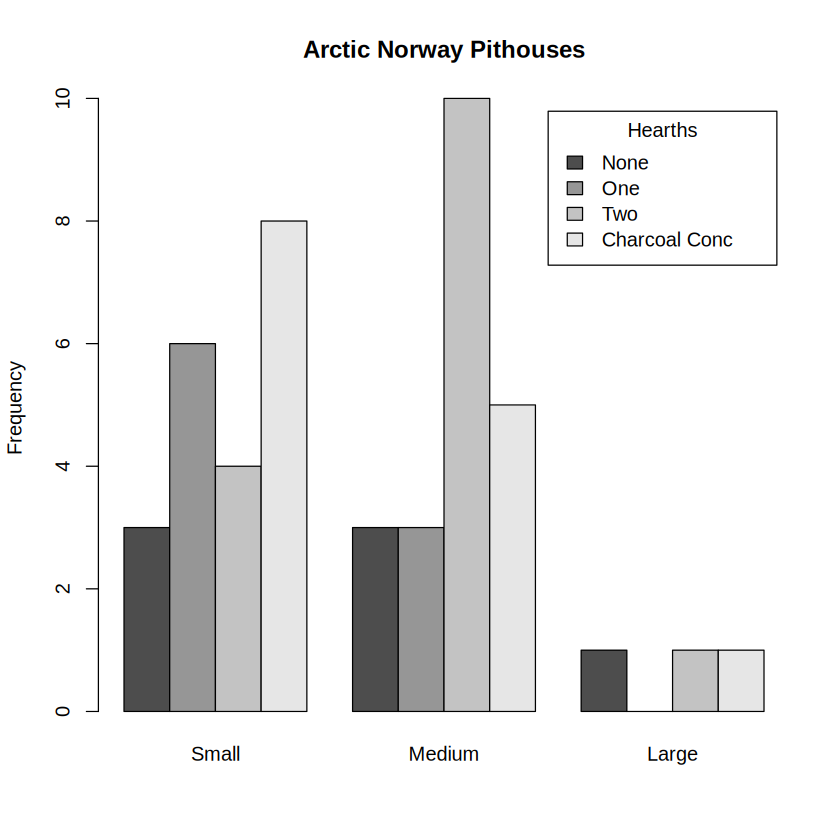

In [21]:

# Then create a barplot of the crosstab. We'll include a legend that describes are different Hearths.
# Remember to export the grab when you're done.
barplot(PitHouses.tbl, ylab="Frequency", main="Arctic Norway Pithouses", beside=TRUE,legend.text=TRUE, args.legend=list(title="Hearths"))


## YOUR TURN #2.

Find a new dataset from the archdata package. Use one of these two create a graph of the data. You can use a scatterplot (plot), a bargraph (barplot), pie chart (pie), or boxplot (boxplot).


In [22]:
# put your stuff in here

# 3. Chi-squared test of association
see also https://www.r-bloggers.com/chi-squared-test/

Do two categories of data seem to 'go together'? And if they do, what might that mean? First we need a contingency table. This will allow us to say, is there an association between x and y?

In [23]:

# Let's say we suspect there's something up with the form of the house and the depth of hearth.
# So we make a new table with just that data:

(table(PitHouses$Orient, PitHouses$Form))

                    
                     Oval Rectangular
  Parallel Coast        6          33
  Gabel Toward Coast    1           5

In [24]:
# Looking at the numbers, it kinda looks like _something_ is going on?
# But that's why we do the test.
#
# Chi-square measures the difference between what we observe in the
# contingency table, and what we would expect, if the distribution
# is normal.

# X² = Σ (O-E)² / E

# Pearson's Chi-squared test is simple to perform.
# The 'correct=FALSE' means, do we want to apply Yates' correction?
# (see https://en.wikipedia.org/wiki/Chi-squared_test for an accessible explanation)
#
# For now, we don't.

chisq.test(PitHouses$Orient, PitHouses$Form, correct=FALSE)

Warning message in chisq.test(PitHouses$Orient, PitHouses$Form, correct = FALSE):
“Chi-squared approximation may be incorrect”



	Pearson's Chi-squared test

data:  PitHouses$Orient and PitHouses$Form
X-squared = 0.007, df = 1, p-value = 0.9


In [25]:
# The X-squared value ('chi-squared', the greek letter X is pronounced with a kind of aspirated ch sound)
# is very small, and the p-value is greater than
# the 95% significance value (0.05) we reject the idea that there is an association.
# (That is, we accept the null hypothesis).

# Now, when we look at the table of values, we see that oval houses with the gabel
# towards the coast only have 1 example. Chi-square is wonky if any of the values
# in a 2x2 table are less than 5, so we can't really conclude anything here.

# Let's see if there's an association between the number of hearths and the form of the house:

table(PitHouses$Hearths, PitHouses$Form)


               
                Oval Rectangular
  None             2           5
  One              2           7
  Two              1          14
  Charcoal Conc    2          12

In [26]:
# Pearson's Chi-squared test
# What's the p value? If it's less than 0.05, then we can reject the null hypothesis.
# (That is, there's an association). If it's greater than 0.05, we accept the null hypothesis.
# (That is, there's no association).

chisq.test(PitHouses$Hearths, PitHouses$Form, correct=FALSE)

Warning message in chisq.test(PitHouses$Hearths, PitHouses$Form, correct = FALSE):
“Chi-squared approximation may be incorrect”



	Pearson's Chi-squared test

data:  PitHouses$Hearths and PitHouses$Form
X-squared = 2, df = 3, p-value = 0.5


In [27]:
# Let's try it on a different dataset, the EWBurials.
# Read up on the data by going to the documentation site, first
# Load and view the data:
data("EWBurials")
View(EWBurials)

,Group,North,West,Age,Sex,Direction,Looking,Goods
,<fct>,<dbl>,<dbl>,<fct>,<fct>,<circular>,<circular>,<fct>
011,2,97.0,90.3,Young Adult,Male,42,283,Present
014,2,100.2,90.6,Young Adult,Male,28,272,Present
015,2,101.7,91.6,Old Adult,Male,350,219,Present
016a,2,101.0,90.5,Young Adult,Male,335,60,Absent
018,2,101.7,90.5,Old Adult,Male,3,86,Present
020,1,95.2,90.5,Young Adult,Male,142,21,Absent
027,2,101.5,93.3,Old Adult,Male,328,244,Absent
034,2,104.4,107.8,Young Adult,Male,351,214,Present
041,2,104.1,109.3,Young Adult,Male,357,91,Absent


In [28]:
# We might imagine that there's an association between burial goods and the different groups:
table(EWBurials$Goods, EWBurials$Group)
# Pearson's Chi-squared test
chisq.test(EWBurials$Goods, EWBurials$Group, correct=FALSE)

# What is the p value? Do you reject the null hypothesis?
# What other associations might you imagine?

         
           1  2
  Absent   9 14
  Present  3 23


	Pearson's Chi-squared test

data:  EWBurials$Goods and EWBurials$Group
X-squared = 5, df = 1, p-value = 0.02


## YOUR TURN #3

Explore some of the other datasets. See if you can find some associations.


In [29]:
# put your stuff here

## YOUR TURN #4

Load up some graveyard data from past students. See what you can accomplish.


In [30]:
library(curl)

graveyards <- read.csv( curl("https://raw.githubusercontent.com/shawngraham/hist3000/master/static/data/graveyards-data.csv"), sep=";" )

View(graveyards)

# Now... explore. Remember to add interesting things to your log for the week!

Using libcurl 8.5.0 with OpenSSL/3.0.13



start,end,Burial.Ground.Name,Burial.Ground.Code,Recording.date,Recorder.Name,Photograph,Grave.monument.Coordinates,X_Grave.monument.Coordinates_latitude,X_Grave.monument.Coordinates_longitude,⋯,Other.Observations.about.the.monument,X_id,X_uuid,X_submission_time,X_validation_status,X_notes,X_status,X_submitted_by,X_tags,X_index
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,⋯,<chr>,<int>,<chr>,<chr>,<lgl>,<lgl>,<chr>,<lgl>,<lgl>,<int>
2020-06-23T13:23:15.653-04:00,2020-06-23T14:10:45.817-04:00,Moodie family plot in Claudette Caine park,MoCC,2020-06-23,Shawn Graham,1592933060533311478207-13_24_29.jpg,45.270846 -75.700946 0 0,45.3,-75.7,⋯,,57171172,17803d33-8407-495f-9348-a48332d18a5d,2020-06-23T18:07:46,NA,NA,submitted_via_web,NA,NA,1
2020-06-23T13:42:04.063-04:00,2020-06-23T13:43:23.285-04:00,Moodie family,Mocc,2020-06-23,Shawn graham,image-13_42_41.jpg,,NA,NA,⋯,,57173373,93f3d25d-cc23-4752-8e8f-1adf2738dc65,2020-06-23T18:19:17,NA,NA,submitted_via_web,NA,NA,2
2020-06-23T13:43:23.390-04:00,2020-06-23T13:55:04.382-04:00,Moodie,Mmoc,2020-06-23,Shawn,,,NA,NA,⋯,,57173374,ddc86ca7-10a0-47a1-8578-9394f6b02ec6,2020-06-23T18:19:18,NA,NA,submitted_via_web,NA,NA,3
2020-09-28T20:11:10.913-04:00,2020-09-28T21:40:30.501-04:00,Sacred Heart Cemetery,MHSH-01,2020-09-27,Dylan Sandford,MHSH-01-21_26_6.jpg,44.482784 -77.67672 0 0,44.5,-77.7,⋯,,68543864,17e5c391-66be-432d-a713-741109e43e92,2020-09-29T01:40:40,NA,NA,submitted_via_web,NA,NA,4
2020-10-03T11:05:46.193-04:00,2020-10-03T11:14:29.991-04:00,Woods Anglican Cemetery,wanc,2020-10-03,Josh Pelletier,16017375912476130308221690131920-11_6_40.jpg,45.349937 -75.631698 0 92.9000015258789,45.3,-75.6,⋯,,69102394,c9ef84f5-6a66-455e-a3f0-6c4492903421,2020-10-03T15:27:23,NA,NA,submitted_via_web,NA,NA,5
2020-10-03T14:31:07.886-04:00,2020-10-03T14:37:26.126-04:00,Saint Isidore Roman Catholic Cemetery,sirc,2020-10-01,Andrew Devenish,100516170_489be3ad-0661-4b9e-a9cc-12f6c7345490-14_31_58.jpeg,45.367905 -75.949656 0 0,45.4,-75.9,⋯,,69118984,782941a2-b65a-47f8-a4de-ff04abb2aed8,2020-10-03T18:37:39,NA,NA,submitted_via_web,NA,NA,6
2020-09-30T14:32:09.105-04:00,2020-10-03T14:26:21.343-04:00,Saint Isidore Roman Catholic Cemetery,sirc,2020-09-30,Andrew Devenish,195666843_284d6d54-f561-4410-827a-f2a012131bb4-14_15_38.jpeg,45.367924 -75.949695 0 0,45.4,-75.9,⋯,,69117725,42b26153-96ae-4873-a5f3-8fe7b6e66609,2020-10-03T18:26:33,NA,NA,submitted_via_web,NA,NA,7
2020-10-03T14:26:21.381-04:00,2020-10-03T14:31:07.857-04:00,Saint Isidore Roman Catholic Cemetery,sirc,2020-10-03,Andrew Devenish,194296809_a3cad0af-3d54-4e5d-86a9-ed123787a2d8-14_27_26.jpeg,45.367939 -75.949704 0 0,45.4,-75.9,⋯,,69118212,56af4c53-81fc-47b3-b906-0fefacbaee1a,2020-10-03T18:31:27,NA,NA,submitted_via_web,NA,NA,8
2020-09-22T14:00:51.842-04:00,2020-09-22T14:55:10.105-04:00,St James Cemetery,STJC,2020-09-22,Teodora Maslenkova,16007997131312022352743898081450-14_35_59.jpg,45.422256 -75.735873 44.69999694824219 254.37399291992188,45.4,-75.7,⋯,,67865290,7b23a657-bf98-426c-b0c4-9607b83624f5,2020-09-22T18:55:26,NA,NA,submitted_via_web,NA,NA,9
